# Membership Churn Model: Training, Evaluation and Live Scoring

This notebook replaces the *simulated* `model_predictions` data (noisy true log-odds from
the data generator) with **real, trained classification models**.

**What this notebook does:**

1. Loads `member_training_features` from PostgreSQL (57,078 renewal-decision events with
   engineered features and ground-truth `churn_flag`).
2. Trains three classifiers — Logistic Regression, Random Forest, Gradient Boosting — on
   a strict **out-of-time** split (train on earlier renewals, test on later ones, so no
   future information leaks into training).
3. Compares them on ROC-AUC, PR-AUC, precision/recall/F1, calibration (Brier score) and a
   confusion matrix, and selects the strongest performer.
4. Extracts genuine feature importance / explainability for each model type.
5. Refits the winning model on the full history, then applies it to **live-computed
   features** pulled directly from the raw activity tables in Postgres (not from the
   training table) for the six existing monthly scoring dates — this mirrors how a real
   pipeline trains once offline and scores current data on a schedule.
6. Writes the real predictions back into `model_predictions`.

**Known, documented simplification:** two of the fourteen model features
(`failed_payment`, `fee_increase`) describe facts about a *specific renewal decision*
that hasn't happened yet at a live scoring date, so they cannot be reconstructed from
current data — they are set to 0 for live scoring. `student_to_full_transition` is
approximated using the member's *historical* grade from `membership_history` as of the
scoring date. This is called out again at the point it's used below.

> Rerunning this notebook end-to-end will **truncate and reload `model_predictions`**,
> which cascades to `ai_insights` (its foreign key points at `model_predictions`). The
> AI insight layer is a separate, not-yet-built phase of this project — see the warning
> cell before the write-back step.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 100

# Project root is this notebook's directory, so `src` imports work without path hacking.
PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "src").exists(), "Run this notebook from the project root."

from src.generators import config as gen_config  # noqa: E402
from src.generators.activity import _segment_id  # noqa: E402
from src.generators.features import RISK_FACTOR_LABELS, engagement_score, risk_category  # noqa: E402

# --- Database connection -----------------------------------------------------------
# Credentials come from .env (gitignored) — see .env.example for the template. Nothing
# secret is hardcoded here or committed.
load_dotenv(PROJECT_ROOT / ".env")
import os

# Built with URL.create() rather than an f-string: the password contains a literal "@",
# which a naively concatenated "user:password@host" string cannot parse correctly (it
# silently produces an empty/invalid host, which makes psycopg2 fall back to a Unix
# socket path that doesn't exist on Windows). URL.create() escapes special characters
# in each component properly.
db_url = URL.create(
    "postgresql+psycopg2",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(db_url)

with engine.connect() as conn:
    who = conn.execute(text("SELECT current_user, current_database()")).fetchone()
print(f"Connected as {who[0]} to database {who[1]}")


Connected as postgres to database membership_intelligence


## 1. Load training data

`member_training_features` has one row per **renewal decision** (not a fixed monthly
cadence) — this is the correct grain for training, because the features were measured
*before* that specific outcome was known. It already lives in Postgres from the earlier
database-loading phase.

`true_churn_probability` is the data generator's own ground-truth log-odds output — using
it as a model input would be leaking the exact answer, the same class of mistake as the
leaked IBM columns caught earlier in this project. It is excluded from the feature set and
kept only as a reference ceiling for evaluation.


In [2]:
raw = pd.read_sql(
    "SELECT * FROM member_training_features ORDER BY observation_date", engine, parse_dates=["observation_date"]
)
print(f"{len(raw):,} renewal-decision rows, {raw['member_id'].nunique():,} distinct members")
print(f"Date range: {raw['observation_date'].min().date()} to {raw['observation_date'].max().date()}")
print(f"Overall churn rate: {raw['churn_flag'].mean():.1%}")

# --- Feature set ---------------------------------------------------------------------
BINARY_FEATURES = [
    "inactive_90_days", "negative_feedback", "failed_payment", "no_event_attendance",
    "declining_logins", "completed_learning", "attended_first_90_days", "auto_renewal",
    "long_tenure", "low_campaign_engagement", "fee_increase", "student_to_full_transition",
    "multi_service_user", "no_recent_advocacy",
]
NUMERIC_FEATURES = [
    "tenure_years", "logins_90d", "logins_prior_90d", "days_since_last_login",
    "web_sessions_90d", "web_sessions_prior_90d", "events_attended_365d",
    "learning_completions_365d", "campaigns_sent_180d", "campaign_open_rate_180d",
    "services_used", "referrals_365d",
]
# min_rating_365d is null whenever the member gave no feedback in the window. A missing
# rating and a bad rating mean different things, so both an indicator and an imputed
# value are kept rather than silently filling with a number that implies "average".
raw["has_recent_feedback"] = raw["min_rating_365d"].notna().astype(int)
raw["min_rating_365d_filled"] = raw["min_rating_365d"].fillna(3.0)  # neutral, only used where the indicator is 0
NUMERIC_FEATURES += ["has_recent_feedback", "min_rating_365d_filled"]

FEATURE_COLUMNS = BINARY_FEATURES + NUMERIC_FEATURES

# Readable labels for the numeric features, extending the binary-feature labels already
# defined in the data generator so importance plots and explanations stay consistent.
FEATURE_LABELS = dict(RISK_FACTOR_LABELS)
FEATURE_LABELS.update({
    "tenure_years": "Membership tenure",
    "logins_90d": "Logins in the last 90 days",
    "logins_prior_90d": "Logins in the prior 90 days",
    "days_since_last_login": "Days since last login",
    "web_sessions_90d": "Website sessions in the last 90 days",
    "web_sessions_prior_90d": "Website sessions in the prior 90 days",
    "events_attended_365d": "Events attended in the last year",
    "learning_completions_365d": "Learning completions in the last year",
    "campaigns_sent_180d": "Campaigns sent in the last 6 months",
    "campaign_open_rate_180d": "Campaign open rate (6 months)",
    "services_used": "Number of services used",
    "referrals_365d": "Referrals made in the last year",
    "has_recent_feedback": "Gave feedback in the last year",
    "min_rating_365d_filled": "Lowest feedback rating in the last year",
})

X = raw[FEATURE_COLUMNS].astype(float)
y = raw["churn_flag"].astype(int)
print(f"\n{len(FEATURE_COLUMNS)} features: {len(BINARY_FEATURES)} binary + {len(NUMERIC_FEATURES)} numeric")
X.head()


57,078 renewal-decision rows, 18,957 distinct members
Date range: 2021-09-01 to 2026-08-31
Overall churn rate: 10.4%

28 features: 14 binary + 14 numeric


,inactive_90_days,negative_feedback,failed_payment,no_event_attendance,declining_logins,completed_learning,attended_first_90_days,auto_renewal,long_tenure,low_campaign_engagement,...,web_sessions_90d,web_sessions_prior_90d,events_attended_365d,learning_completions_365d,campaigns_sent_180d,campaign_open_rate_180d,services_used,referrals_365d,has_recent_feedback,min_rating_365d_filled
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0


## 2. Out-of-time train/test split

A random row-wise split would let the model see renewal decisions from *after* the test
period during training, which no real deployment could ever do. Instead, the most recent
25% of renewal decisions by date are held out entirely — the model is trained only on
decisions that happened before the test window starts.


In [3]:
CUTOFF = raw["observation_date"].quantile(0.75)
train_mask = raw["observation_date"] < CUTOFF
test_mask = ~train_mask

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
true_prob_test = raw.loc[test_mask, "true_churn_probability"]

print(f"Cutoff date: {CUTOFF.date()}")
print(f"Train: {len(X_train):,} rows, {y_train.mean():.1%} churn, "
      f"{raw.loc[train_mask, 'observation_date'].min().date()} to {raw.loc[train_mask, 'observation_date'].max().date()}")
print(f"Test:  {len(X_test):,} rows, {y_test.mean():.1%} churn, "
      f"{raw.loc[test_mask, 'observation_date'].min().date()} to {raw.loc[test_mask, 'observation_date'].max().date()}")

from sklearn.metrics import roc_auc_score

ceiling_auc = roc_auc_score(y_test, true_prob_test)
print(f"\nCeiling AUC on the test period (from the generator's true propensity): {ceiling_auc:.3f}")
print("No model below should legitimately exceed this by much — it reflects the irreducible")
print("noise the data-generating process itself injects into the outcome.")


Cutoff date: 2025-09-05
Train: 42,789 rows, 10.6% churn, 2021-09-01 to 2025-09-04
Test:  14,289 rows, 9.5% churn, 2025-09-05 to 2026-08-31



Ceiling AUC on the test period (from the generator's true propensity): 0.762
No model below should legitimately exceed this by much — it reflects the irreducible
noise the data-generating process itself injects into the outcome.


## 3. Train three classifiers

All three see the same 26 features and the same train/test split, so any performance
difference is attributable to the model, not the data. Logistic Regression is wrapped
in a pipeline with standardisation, since it's scale-sensitive; the tree-based models
are not.


In [4]:
from time import perf_counter

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, max_depth=8, min_samples_leaf=20, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42
    ),
}

fitted = {}
for name, model in models.items():
    t0 = perf_counter()
    model.fit(X_train, y_train)
    fitted[name] = model
    print(f"{name:<20} trained in {perf_counter() - t0:5.1f}s")


Logistic Regression  trained in   0.5s


Random Forest        trained in  12.7s


Gradient Boosting    trained in  47.3s


## 4. Out-of-time evaluation and comparison

Metrics, in order of what matters most for this use case:

- **ROC-AUC** — overall ranking quality, comparable directly to the 0.76-ish ceiling above.
- **PR-AUC (average precision)** — more informative than ROC-AUC under class imbalance
  (~9-10% churn per renewal decision); rewards models that rank true churners highly
  among the minority class specifically.
- **Brier score** — calibration. This matters here specifically because the probability
  itself feeds `predicted_lifetime_value` downstream, not just the ranking.
- **Precision / recall / F1** at the project's existing operating threshold
  (`config.PREDICTION_THRESHOLD = 0.25`, chosen to favour recall for a retention
  campaign) and confusion matrices, so the comparison is grounded in an actual decision
  rule rather than only threshold-free rank metrics.


,roc_auc,pr_auc,brier_score,precision@0.25,recall@0.25,f1@0.25
model,,,,,,
Logistic Regression,0.761800,0.2906,0.0770,0.3558,0.2831,0.3153
Random Forest,0.752600,0.2721,0.0782,0.3340,0.2404,0.2796
Gradient Boosting,0.757200,0.2760,0.0777,0.3370,0.2684,0.2988
Ceiling (true propensity),0.761713,NaN,NaN,NaN,NaN,NaN


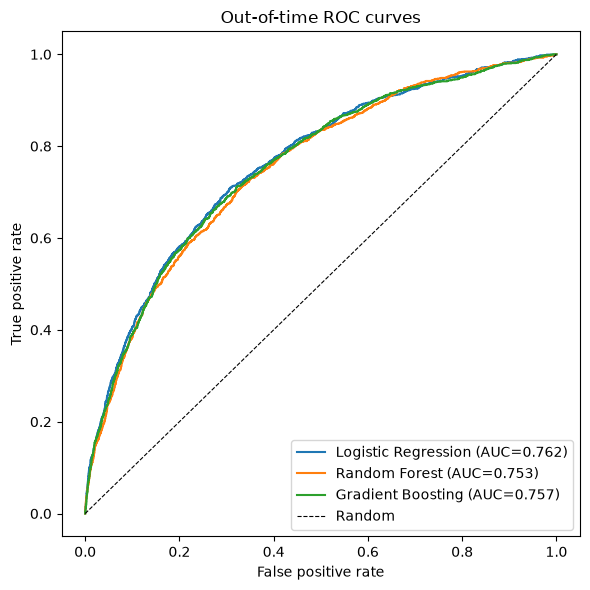

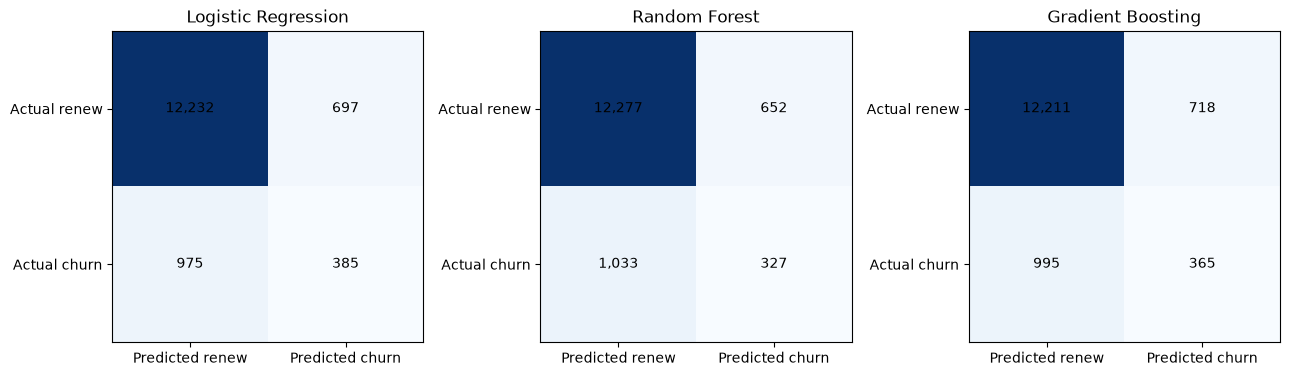

In [5]:
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)

THRESHOLD = gen_config.PREDICTION_THRESHOLD  # 0.25, matches the rest of the project

rows = []
proba_test = {}
for name, model in fitted.items():
    p = model.predict_proba(X_test)[:, 1]
    proba_test[name] = p
    pred = (p >= THRESHOLD).astype(int)
    rows.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, p),
        "pr_auc": average_precision_score(y_test, p),
        "brier_score": brier_score_loss(y_test, p),
        "precision@0.25": precision_score(y_test, pred),
        "recall@0.25": recall_score(y_test, pred),
        "f1@0.25": f1_score(y_test, pred),
    })

comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison.loc["Ceiling (true propensity)"] = [ceiling_auc, np.nan, np.nan, np.nan, np.nan, np.nan]
display(comparison)

# ROC curves
plt.figure(figsize=(6, 6))
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Out-of-time ROC curves")
plt.legend()
plt.tight_layout()
plt.show()

# Confusion matrices at the operating threshold
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, p) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_test, (p >= THRESHOLD).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
    ax.set_xticks([0, 1], ["Predicted renew", "Predicted churn"])
    ax.set_yticks([0, 1], ["Actual renew", "Actual churn"])
    ax.set_title(name)
plt.tight_layout()
plt.show()


In [6]:
model_rows = comparison.drop(index="Ceiling (true propensity)")
WINNER = model_rows["roc_auc"].idxmax()
runner_up = model_rows["roc_auc"].drop(index=WINNER).idxmax()
gap = model_rows.loc[WINNER, "roc_auc"] - model_rows.loc[runner_up, "roc_auc"]

print(f"Winner: {WINNER}")
print(f"  ROC-AUC {model_rows.loc[WINNER, 'roc_auc']:.4f} vs runner-up {runner_up} at "
      f"{model_rows.loc[runner_up, 'roc_auc']:.4f} (gap {gap:+.4f})")
print(f"  PR-AUC {model_rows.loc[WINNER, 'pr_auc']:.4f}, Brier {model_rows.loc[WINNER, 'brier_score']:.4f}")
print(f"  For reference, the ceiling AUC from the true generating process is {ceiling_auc:.4f}")

winner_model = fitted[WINNER]


Winner: Logistic Regression
  ROC-AUC 0.7618 vs runner-up Gradient Boosting at 0.7572 (gap +0.0046)
  PR-AUC 0.2906, Brier 0.0770
  For reference, the ceiling AUC from the true generating process is 0.7617


## 5. Feature importance and explainability

Each model type exposes importance differently, so each is read on its own terms:

- **Logistic Regression** — standardised coefficients convert directly to **odds ratios**
  (`exp(coefficient)`): an odds ratio of 1.8 means that feature multiplies the odds of
  churn by 1.8 for a one-standard-deviation increase, holding the others fixed.
- **Random Forest / Gradient Boosting** — mean decrease in impurity (built-in
  `feature_importances_`), which ranks features by how much they reduce prediction error
  across all trees, without a sign (it can't say *which direction* a feature pushes risk).

**Permutation importance** is also run for the winning model specifically: it measures the
actual drop in held-out ROC-AUC when a feature's values are shuffled, which is
model-agnostic and a useful cross-check against the model's own built-in importance.


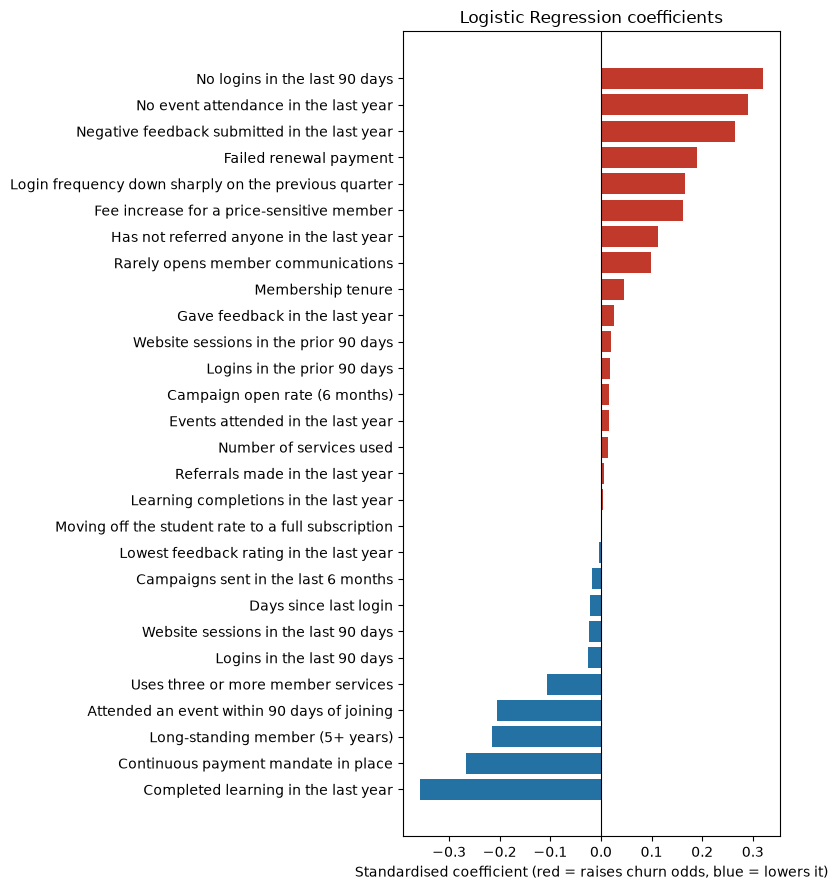

Largest odds ratios (Logistic Regression):
inactive_90_days       1.377
no_event_attendance    1.338
negative_feedback      1.303
failed_payment         1.209
declining_logins       1.182

Smallest odds ratios (most protective):
completed_learning        0.700
auto_renewal              0.767
long_tenure               0.806
attended_first_90_days    0.814
multi_service_user        0.899


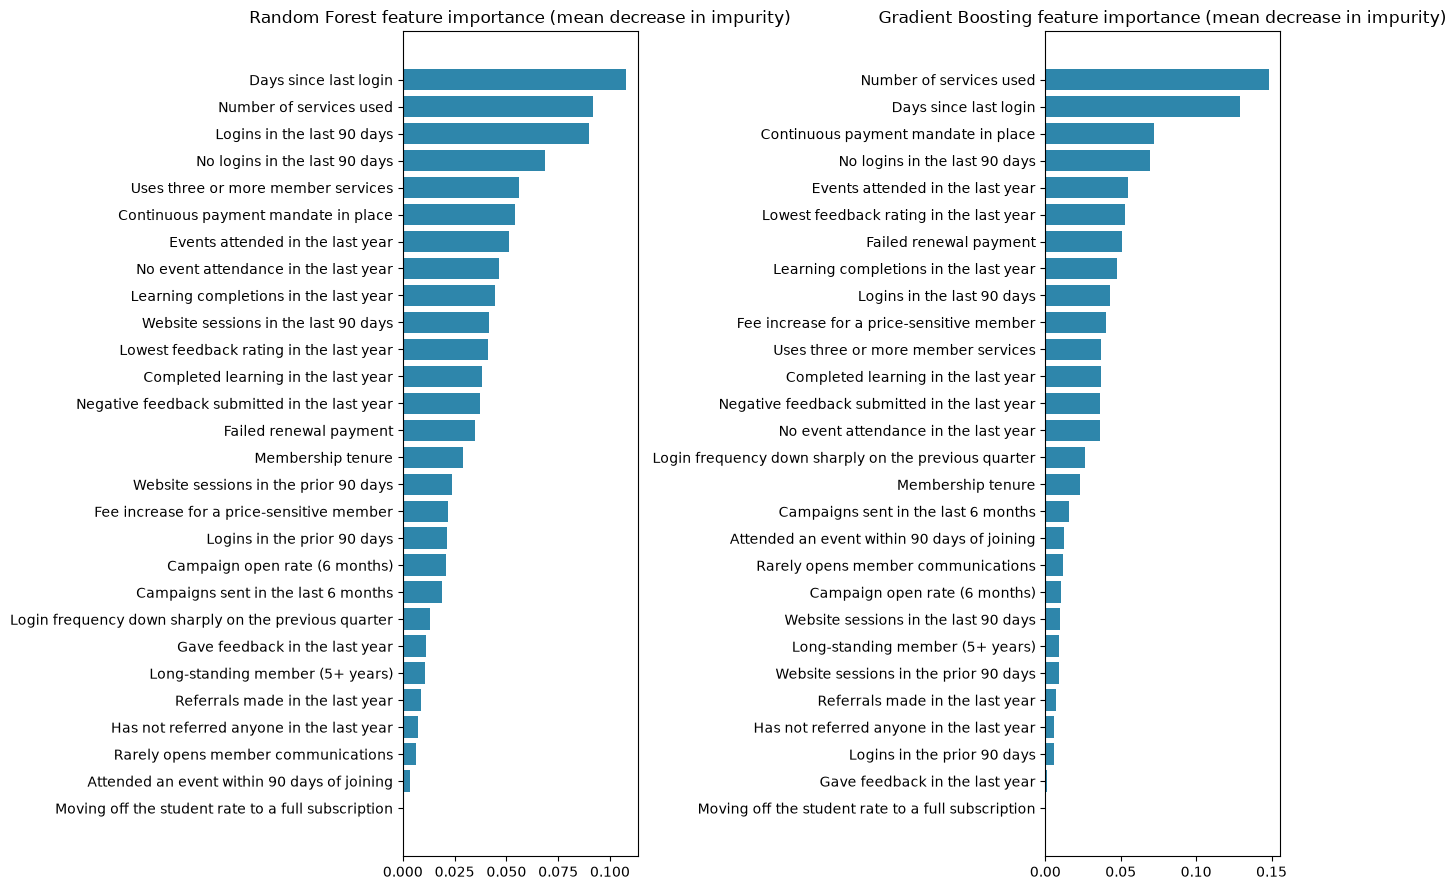


Permutation importance for the winner (Logistic Regression), top 8 (drop in ROC-AUC when shuffled):
completed_learning        0.0296
inactive_90_days          0.0264
no_event_attendance       0.0199
auto_renewal              0.0151
negative_feedback         0.0137
attended_first_90_days    0.0130
failed_payment            0.0115
long_tenure               0.0088


In [7]:
# --- Logistic Regression: odds ratios --------------------------------------------------
lr_clf = fitted["Logistic Regression"].named_steps["clf"]
lr_coef = pd.Series(lr_clf.coef_[0], index=FEATURE_COLUMNS).sort_values()
lr_odds = np.exp(lr_coef)

fig, ax = plt.subplots(figsize=(8, 9))
colors = ["#c0392b" if v > 0 else "#2471a3" for v in lr_coef]
ax.barh([FEATURE_LABELS.get(f, f) for f in lr_coef.index], lr_coef.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardised coefficient (red = raises churn odds, blue = lowers it)")
ax.set_title("Logistic Regression coefficients")
plt.tight_layout()
plt.show()

print("Largest odds ratios (Logistic Regression):")
print(lr_odds.sort_values(ascending=False).head(5).round(3).to_string())
print("\nSmallest odds ratios (most protective):")
print(lr_odds.sort_values().head(5).round(3).to_string())

# --- Tree-based importances --------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
for ax, name in zip(axes, ["Random Forest", "Gradient Boosting"]):
    imp = pd.Series(fitted[name].feature_importances_, index=FEATURE_COLUMNS).sort_values()
    ax.barh([FEATURE_LABELS.get(f, f) for f in imp.index], imp.values, color="#2e86ab")
    ax.set_title(f"{name} feature importance (mean decrease in impurity)")
plt.tight_layout()
plt.show()

# --- Permutation importance for the winner -----------------------------------------
from sklearn.inspection import permutation_importance

perm = permutation_importance(winner_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURE_COLUMNS).sort_values(ascending=False)
print(f"\nPermutation importance for the winner ({WINNER}), top 8 (drop in ROC-AUC when shuffled):")
print(perm_imp.head(8).round(4).to_string())


## 6. Refit the winner on the full history

Model selection is now finished — its evaluation was done honestly, on data the model
never saw during training. Standard practice from here is to refit the *same*
architecture and hyperparameters on **all** available history (train + test combined)
before deploying it, since a production model should learn from every renewal decision
on record, not withhold the most recent quarter of it forever. The out-of-time metrics
above remain the honest measure of how this model performs on unseen data; they are not
recomputed against this refit.


In [8]:
from sklearn.base import clone

deployed_model = clone(models[WINNER])
deployed_model.fit(X, y)

MODEL_VERSION = "2.0.0"  # real trained model; 1.x was the simulated baseline
MODEL_NAME = {
    "Logistic Regression": "membership_churn_logreg",
    "Random Forest": "membership_churn_rf",
    "Gradient Boosting": "membership_churn_gbm",
}[WINNER]
print(f"Deployed model: {MODEL_NAME} v{MODEL_VERSION} ({WINNER}), refit on all {len(X):,} historical renewal decisions")


Deployed model: membership_churn_logreg v2.0.0 (Logistic Regression), refit on all 57,078 historical renewal decisions


## 7. Live feature engineering

`member_training_features` is a **training** artefact — one row per renewal decision,
built by the data generator itself. Deploying the model correctly means computing the
*same* feature definitions independently, straight from the raw activity tables
(`login_history`, `website_activity`, `event_attendance`, `learning_activity`,
`marketing_engagement`, `member_feedback`, `member_referrals`), as of an arbitrary
scoring date. That is what actually happens in a production system: train once
offline on historical outcomes, then score current data on a schedule using a feature
pipeline that has no access to the training table at all.

The function below reimplements `compute_features()` from
`src/generators/features.py` as SQL aggregates. Three features cannot be reconstructed
exactly at a live scoring date and are handled as documented approximations:

- **`failed_payment`** and **`fee_increase`** describe facts about a *specific renewal
  decision* that, at most scoring dates, hasn't happened yet — there is nothing in the
  schema that lets a live query know in advance whether an upcoming renewal will see a
  failed payment or a large fee rise. Both are set to `0`.
- **`student_to_full_transition`** uses the member's grade *as it stood on the scoring
  date* (from `membership_history`, not the member's current/final grade), which is a
  faithful reconstruction rather than an approximation.


In [9]:
def compute_live_features(cutoff: pd.Timestamp) -> pd.DataFrame:
    """Compute the full feature set for every member active as of `cutoff`, straight
    from the raw activity tables. Mirrors compute_features() in the data generator."""
    p = {"cutoff": cutoff}

    base = pd.read_sql(text("""
        SELECT member_id, join_date, auto_renewal, annual_fee
        FROM members
        WHERE join_date <= :cutoff - INTERVAL '30 days'
          AND (churn_date IS NULL OR churn_date > :cutoff)
    """), engine, params=p, parse_dates=["join_date"])

    grade = pd.read_sql(text("""
        SELECT member_id, membership_type
        FROM membership_history
        WHERE effective_from <= :cutoff AND (effective_to IS NULL OR effective_to >= :cutoff)
    """), engine, params=p)

    logins = pd.read_sql(text("""
        SELECT member_id,
               COUNT(*) FILTER (WHERE login_timestamp >= :cutoff - INTERVAL '90 days') AS logins_90d,
               COUNT(*) FILTER (WHERE login_timestamp >= :cutoff - INTERVAL '180 days'
                                 AND login_timestamp < :cutoff - INTERVAL '90 days') AS logins_prior_90d,
               MAX(login_timestamp) AS last_login_ts
        FROM login_history
        WHERE login_timestamp < :cutoff
        GROUP BY member_id
    """), engine, params=p, parse_dates=["last_login_ts"])

    web = pd.read_sql(text("""
        SELECT member_id,
               SUM(session_count) FILTER (WHERE activity_date >= :cutoff - INTERVAL '90 days') AS web_sessions_90d,
               SUM(session_count) FILTER (WHERE activity_date >= :cutoff - INTERVAL '180 days'
                                            AND activity_date < :cutoff - INTERVAL '90 days') AS web_sessions_prior_90d
        FROM website_activity
        WHERE activity_date >= :cutoff - INTERVAL '180 days' AND activity_date < :cutoff
        GROUP BY member_id
    """), engine, params=p)

    events_365 = pd.read_sql(text("""
        SELECT ea.member_id, COUNT(*) AS events_attended_365d
        FROM event_attendance ea JOIN events e ON e.event_id = ea.event_id
        WHERE ea.attendance_status = 'Attended'
          AND e.event_date >= :cutoff - INTERVAL '365 days' AND e.event_date < :cutoff
        GROUP BY ea.member_id
    """), engine, params=p)

    events_first90 = pd.read_sql(text("""
        SELECT DISTINCT ea.member_id
        FROM event_attendance ea
        JOIN events e ON e.event_id = ea.event_id
        JOIN members m ON m.member_id = ea.member_id
        WHERE ea.attendance_status = 'Attended' AND e.event_date < :cutoff
          AND e.event_date >= m.join_date AND e.event_date < m.join_date + INTERVAL '90 days'
    """), engine, params=p)

    learning = pd.read_sql(text("""
        SELECT member_id,
               COUNT(*) FILTER (WHERE completion_status = 'Completed') AS learning_completions_365d,
               COUNT(*) AS learning_any_365d
        FROM learning_activity
        WHERE activity_date >= :cutoff - INTERVAL '365 days' AND activity_date < :cutoff
        GROUP BY member_id
    """), engine, params=p)

    marketing = pd.read_sql(text("""
        SELECT member_id, COUNT(*) AS campaigns_sent_180d,
               AVG(CASE WHEN opened THEN 1.0 ELSE 0.0 END) AS campaign_open_rate_180d
        FROM marketing_engagement
        WHERE sent_date >= :cutoff - INTERVAL '180 days' AND sent_date < :cutoff
        GROUP BY member_id
    """), engine, params=p)

    feedback = pd.read_sql(text("""
        SELECT member_id, MIN(rating) AS min_rating_365d
        FROM member_feedback
        WHERE submitted_date >= :cutoff - INTERVAL '365 days' AND submitted_date < :cutoff
        GROUP BY member_id
    """), engine, params=p)

    referrals = pd.read_sql(text("""
        SELECT referring_member_id AS member_id, COUNT(*) AS referrals_365d
        FROM member_referrals
        WHERE referral_date >= :cutoff - INTERVAL '365 days' AND referral_date < :cutoff
        GROUP BY referring_member_id
    """), engine, params=p)

    df = base.merge(grade, on="member_id", how="left")
    for part in (logins, web, events_365, learning, marketing, feedback, referrals):
        df = df.merge(part, on="member_id", how="left")
    df["attended_first_90_days"] = df["member_id"].isin(events_first90["member_id"]).astype(int)

    count_cols = ["logins_90d", "logins_prior_90d", "web_sessions_90d", "web_sessions_prior_90d",
                  "events_attended_365d", "learning_completions_365d", "learning_any_365d",
                  "campaigns_sent_180d", "referrals_365d"]
    df[count_cols] = df[count_cols].fillna(0)
    df["campaign_open_rate_180d"] = df["campaign_open_rate_180d"].fillna(0.0)

    df["tenure_years"] = (cutoff - df["join_date"]).dt.days / 365.25
    df["days_since_last_login"] = (cutoff - df["last_login_ts"]).dt.days
    df["days_since_last_login"] = df["days_since_last_login"].fillna(999).astype(int)

    df["services_used"] = (
        (df["logins_90d"] > 0).astype(int) + (df["events_attended_365d"] > 0).astype(int)
        + (df["learning_any_365d"] > 0).astype(int) + (df["campaign_open_rate_180d"] > 0.2).astype(int)
    )
    df["has_recent_feedback"] = df["min_rating_365d"].notna().astype(int)
    df["min_rating_365d_filled"] = df["min_rating_365d"].fillna(3.0)

    df["inactive_90_days"] = (df["logins_90d"] == 0).astype(int)
    df["negative_feedback"] = (df["min_rating_365d"] <= 2).fillna(False).astype(int)
    df["failed_payment"] = 0          # documented approximation, see markdown above
    df["fee_increase"] = 0            # documented approximation, see markdown above
    df["no_event_attendance"] = (df["events_attended_365d"] == 0).astype(int)
    df["declining_logins"] = ((df["logins_prior_90d"] >= 3) & (df["logins_90d"] < 0.6 * df["logins_prior_90d"])).astype(int)
    df["completed_learning"] = (df["learning_completions_365d"] >= 1).astype(int)
    df["auto_renewal"] = df["auto_renewal"].astype(int)
    df["long_tenure"] = (df["tenure_years"] >= 5.0).astype(int)
    df["low_campaign_engagement"] = ((df["campaigns_sent_180d"] >= 4) & (df["campaign_open_rate_180d"] < 0.15)).astype(int)
    df["student_to_full_transition"] = ((df["membership_type"] == "Student") & (df["tenure_years"] >= 3.0)).astype(int)
    df["multi_service_user"] = (df["services_used"] >= 3).astype(int)
    df["no_recent_advocacy"] = (df["referrals_365d"] == 0).astype(int)

    return df[["member_id", "join_date", "annual_fee"] + FEATURE_COLUMNS]


# Sanity check on the most recent cutoff (should resemble the training-table averages).
_sample = compute_live_features(raw["observation_date"].max())
print(f"{len(_sample):,} members active as of {raw['observation_date'].max().date()}")
_sample[FEATURE_COLUMNS].mean().round(3)


19,086 members active as of 2026-08-31


inactive_90_days               0.097
negative_feedback              0.111
failed_payment                 0.000
no_event_attendance            0.341
declining_logins               0.133
completed_learning             0.500
attended_first_90_days         0.218
auto_renewal                   0.563
long_tenure                    0.267
low_campaign_engagement        0.064
fee_increase                   0.000
student_to_full_transition     0.000
multi_service_user             0.589
no_recent_advocacy             0.648
tenure_years                   3.608
logins_90d                     8.722
logins_prior_90d               8.363
days_since_last_login         68.070
web_sessions_90d              10.481
web_sessions_prior_90d        11.074
events_attended_365d           2.609
learning_completions_365d      1.265
campaigns_sent_180d            5.782
campaign_open_rate_180d        0.192
services_used                  2.552
referrals_365d                 0.630
has_recent_feedback            0.287
m

## 8. Score the existing monthly runs with real, live-computed features

The six `prediction_run_id` values already in the database are preserved — this keeps
the table's grain and any downstream Power BI model compatible — but every feature
behind them is now computed fresh from the raw activity tables via
`compute_live_features()`, not copied from the training table.


In [10]:
# Read-only: capture the existing run identifiers before anything is written.
existing_runs = pd.read_sql(
    "SELECT DISTINCT prediction_run_id, prediction_date FROM model_predictions ORDER BY prediction_date",
    engine, parse_dates=["prediction_date"],
)
print("Existing scoring runs (grain preserved):")
display(existing_runs)

RISK_FEATURES_SET = [f for f in gen_config.CHURN_COEFFICIENTS if f != "intercept"]
from src.generators.features import PROTECTIVE_FEATURES, RISK_FEATURES  # noqa: E402

risk_weight = perm_imp.reindex(RISK_FEATURES).fillna(0)


def top_risk_factors_for(df_scored: pd.DataFrame, k: int = 3) -> pd.DataFrame:
    """Rank each row's active risk-raising flags by the winning model's own permutation
    importance, i.e. genuine model-derived explanations rather than the DGP's asserted
    coefficients. Restricted to the same nine risk-raising flags the original design
    used, so the schema and semantics stay directly comparable to before."""
    active = df_scored[RISK_FEATURES].to_numpy().astype(bool)
    weights = risk_weight[RISK_FEATURES].to_numpy()
    out = np.full((len(df_scored), k), "", dtype=object)
    for i in range(len(df_scored)):
        cand = [RISK_FEATURES[j] for j in np.argsort(-weights * active[i])[: sum(active[i])]]
        for j, f in enumerate(cand[:k]):
            out[i, j] = RISK_FACTOR_LABELS[f]
    return pd.DataFrame(out, columns=[f"top_risk_factor_{i+1}" for i in range(k)], index=df_scored.index)


scored_runs = []
for _, run in existing_runs.iterrows():
    live = compute_live_features(run["prediction_date"])
    proba = deployed_model.predict_proba(live[FEATURE_COLUMNS])[:, 1]

    out = live[["member_id", "annual_fee"]].copy()
    out["prediction_run_id"] = run["prediction_run_id"]
    out["prediction_date"] = run["prediction_date"]
    out["churn_probability"] = np.round(proba, 4)
    out["risk_category"] = [risk_category(p) for p in proba]
    out["predicted_churn"] = (proba >= THRESHOLD).astype(int)
    out["engagement_score"] = live[FEATURE_COLUMNS].apply(lambda r: engagement_score(r.to_dict()), axis=1)

    expected_years = np.minimum(1.0 / np.maximum(proba, 0.06), 12.0)
    out["predicted_lifetime_value"] = np.round(live["annual_fee"] * expected_years * gen_config.CONTRIBUTION_MARGIN, 2)

    seg_feats = live[["tenure_years", "events_attended_365d", "learning_completions_365d", "auto_renewal"]]
    out["segment_id"] = [
        _segment_id({**row._asdict(), "auto_renewal": bool(row.auto_renewal)}, p, s)
        for row, p, s in zip(seg_feats.itertuples(index=False), proba, out["engagement_score"])
    ]

    risk_cols = top_risk_factors_for(live)
    out = pd.concat([out.reset_index(drop=True), risk_cols.reset_index(drop=True)], axis=1)

    scored_runs.append(out)
    print(f"{run['prediction_run_id']}: {len(out):,} members scored, "
          f"{(out['risk_category']=='High').sum():,} high-risk")

new_predictions = pd.concat(scored_runs, ignore_index=True)
new_predictions["model_name"] = MODEL_NAME
new_predictions["model_version"] = MODEL_VERSION
new_predictions = new_predictions.drop(columns=["annual_fee"])
print(f"\n{len(new_predictions):,} total prediction rows assembled")
new_predictions.head()


Existing scoring runs (grain preserved):


,prediction_run_id,prediction_date
0,RUN-2026-03-31,2026-03-31
1,RUN-2026-04-30,2026-04-30
2,RUN-2026-05-31,2026-05-31
3,RUN-2026-06-30,2026-06-30
4,RUN-2026-07-31,2026-07-31
5,RUN-2026-08-31,2026-08-31


RUN-2026-03-31: 15,677 members scored, 803 high-risk


RUN-2026-04-30: 16,063 members scored, 767 high-risk


RUN-2026-05-31: 16,567 members scored, 738 high-risk


RUN-2026-06-30: 17,173 members scored, 773 high-risk


RUN-2026-07-31: 18,049 members scored, 798 high-risk


RUN-2026-08-31: 19,086 members scored, 993 high-risk

102,615 total prediction rows assembled


,member_id,prediction_run_id,prediction_date,churn_probability,risk_category,predicted_churn,engagement_score,predicted_lifetime_value,segment_id,top_risk_factor_1,top_risk_factor_2,top_risk_factor_3,model_name,model_version
0,M0000001,RUN-2026-03-31,2026-03-31,0.0436,Low,0,80.0,1365.72,1,Negative feedback submitted in the last year,Has not referred anyone in the last year,,membership_churn_logreg,2.0.0
1,M0000002,RUN-2026-03-31,2026-03-31,0.0490,Low,0,62.7,1110.67,1,Has not referred anyone in the last year,,,membership_churn_logreg,2.0.0
2,M0000005,RUN-2026-03-31,2026-03-31,0.0659,Low,0,57.6,3783.80,4,Negative feedback submitted in the last year,Has not referred anyone in the last year,,membership_churn_logreg,2.0.0
3,M0000007,RUN-2026-03-31,2026-03-31,0.3474,High,1,6.0,248.72,7,No logins in the last 90 days,No event attendance in the last year,Has not referred anyone in the last year,membership_churn_logreg,2.0.0
4,M0000008,RUN-2026-03-31,2026-03-31,0.1189,Medium,0,53.5,1302.80,4,Rarely opens member communications,,,membership_churn_logreg,2.0.0


## 9. Write back to `model_predictions`

**This is destructive.** `model_predictions` is truncated and reloaded with the rows
built above. Because `ai_insights.prediction_run_id` has a composite foreign key onto
`model_predictions (prediction_run_id, member_id)`, truncating the parent requires
truncating `ai_insights` too — its rows are template-generated placeholder text tied to
the *old* simulated `prediction_run_id`/`member_id` pairs anyway, and would become
orphaned the moment the real predictions replace them. The AI insight layer is a
separate phase of this project, not yet built; this just clears the placeholder rows
rather than leaving them silently pointing at stale scores.

Run the next cell only when ready to commit this change.


In [11]:
final = new_predictions.copy()
final.insert(0, "prediction_id", [f"PR{i+1:09d}" for i in range(len(final))])
final = final[[
    "prediction_id", "prediction_run_id", "member_id", "prediction_date", "churn_probability",
    "risk_category", "predicted_churn", "engagement_score", "predicted_lifetime_value", "segment_id",
    "model_name", "model_version", "top_risk_factor_1", "top_risk_factor_2", "top_risk_factor_3",
]]
assert final["prediction_id"].is_unique
assert not final.duplicated(subset=["prediction_run_id", "member_id"]).any(), "would violate mp_run_member_uq"
assert final["churn_probability"].between(0, 1).all()

with engine.begin() as conn:
    ai_insights_removed = conn.execute(text("SELECT COUNT(*) FROM ai_insights")).scalar()
    old_predictions_removed = conn.execute(text("SELECT COUNT(*) FROM model_predictions")).scalar()
    # Both tables in one TRUNCATE: Postgres refuses to truncate a table that another
    # table's foreign key still references, even inside the same transaction, unless
    # the referencing table is truncated in the same statement (or CASCADE is used).
    conn.execute(text("TRUNCATE TABLE ai_insights, model_predictions"))
    final.to_sql("model_predictions", conn, if_exists="append", index=False, method="multi", chunksize=5000)

print(f"Removed {old_predictions_removed:,} simulated predictions and {ai_insights_removed:,} template insights.")
print(f"Wrote {len(final):,} real predictions from {MODEL_NAME} v{MODEL_VERSION}.")


Removed 102,615 simulated predictions and 0 template insights.
Wrote 102,615 real predictions from membership_churn_logreg v2.0.0.


## 10. Persist the model

Saved so the live-scoring step above can be rerun later (e.g. for a future monthly run)
without retraining.


In [12]:
import json

import joblib

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(deployed_model, MODELS_DIR / f"{MODEL_NAME}_v{MODEL_VERSION}.joblib")

metadata = {
    "model_name": MODEL_NAME,
    "model_version": MODEL_VERSION,
    "model_type": WINNER,
    "feature_columns": FEATURE_COLUMNS,
    "decision_threshold": THRESHOLD,
    "trained_on_rows": int(len(X)),
    "training_date_range": [str(raw["observation_date"].min().date()), str(raw["observation_date"].max().date())],
    "out_of_time_metrics": comparison.loc[WINNER].to_dict(),
    "ceiling_auc": float(ceiling_auc),
    "all_models_compared": comparison.to_dict(orient="index"),
}
with open(MODELS_DIR / f"{MODEL_NAME}_v{MODEL_VERSION}.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print(f"Saved model + metadata to {MODELS_DIR}")


Saved model + metadata to C:\Users\Student\End-to-End-LLM-Powered-Customer-Intelligence-Pipeline\models


## 11. Validate against the database — including real subsequent outcomes

The out-of-time metrics in section 4 validate the *model*. This validates the *deployed
pipeline* — live feature engineering plus the model together — against what actually
happened afterwards. Since every member's real `churn_date` is known, each historical
run's risk bands can be checked against **genuine subsequent outcomes**: did the members
this pipeline called "High risk" in, say, March 2026 actually go on to churn more than
the ones it called "Low risk"? This is a stronger end-to-end check than the offline
metrics alone, because it exercises the SQL feature engineering, not just the model.


In [13]:
# Row counts and grain check, straight from the database (not the DataFrame still in memory).
check1 = pd.read_sql("""
    SELECT prediction_run_id, COUNT(*) AS members, COUNT(DISTINCT member_id) AS distinct_members
    FROM model_predictions GROUP BY prediction_run_id ORDER BY prediction_run_id
""", engine)
print("Grain check (members should equal distinct_members on every row):")
display(check1)

print(f"\nai_insights rows remaining (should be 0 until the LLM layer is (re)built): "
      f"{pd.read_sql('SELECT COUNT(*) FROM ai_insights', engine).iloc[0, 0]}")

# The dataset's activity window ends at the as-of date, so only earlier runs have any
# follow-up period in which a subsequent churn could actually appear in the data — the
# final run (2026-08-31) *is* the as-of date, so it necessarily shows 0% by construction.
earliest_run = existing_runs.iloc[0]
print(f"\nSubsequent-outcome check for the earliest run ({earliest_run['prediction_run_id']}, "
      f"~5 months of follow-up before the dataset's as-of date):")
check2 = pd.read_sql(text("""
    SELECT mp.risk_category, COUNT(*) AS members,
           ROUND(100.0 * SUM(CASE WHEN m.churn_date IS NOT NULL AND m.churn_date > mp.prediction_date
                                   THEN 1 ELSE 0 END) / COUNT(*), 1) AS subsequently_churned_pct
    FROM model_predictions mp JOIN members m ON m.member_id = mp.member_id
    WHERE mp.prediction_run_id = :run_id
    GROUP BY mp.risk_category ORDER BY subsequently_churned_pct DESC
"""), engine, params={"run_id": earliest_run["prediction_run_id"]})
display(check2)


Grain check (members should equal distinct_members on every row):


,prediction_run_id,members,distinct_members
0,RUN-2026-03-31,15677,15677
1,RUN-2026-04-30,16063,16063
2,RUN-2026-05-31,16567,16567
3,RUN-2026-06-30,17173,17173
4,RUN-2026-07-31,18049,18049
5,RUN-2026-08-31,19086,19086



ai_insights rows remaining (should be 0 until the LLM layer is (re)built): 0

Subsequent-outcome check for the earliest run (RUN-2026-03-31, ~5 months of follow-up before the dataset's as-of date):


,risk_category,members,subsequently_churned_pct
0,High,803,13.2
1,Medium,3833,5.7
2,Low,11041,2.1


## 12. AI insight generation — a real local LLM layer

`ai_insights` is currently empty (truncated in step 9, since its foreign key pointed at
the old simulated predictions). This section rebuilds it for real, following the
architecture set out in `Architecture.md`: an LLM runs **outside** Power BI, is given
**structured facts** pulled from `model_predictions` (not raw prompting from scratch),
its output is validated, and only then is it persisted to Postgres. Power BI's job stays
limited to filtering and displaying rows that already exist in the database.

**Model.** `Open-Model-Recommendations.md` was written for this exact machine (Intel
i5-7200U, 2 cores / 4 threads, 8GB RAM, CPU-only) and recommends a 1.5–3B instruction
model as the practical sweet spot. Ollama's library doesn't carry the literal tag
"Qwen3.5 2B" the doc names (that generation of Qwen isn't published there); the closest
real equivalent in the same size class is **`qwen2.5:1.5b`**, which this notebook uses.
It's queried through Ollama's local HTTP API (`localhost:11434`) with `format: "json"`
to constrain the model to structured output, since free-form text from a 1.5B model is
otherwise inconsistent enough to make automated validation unreliable.

**Scope.** Benchmarked directly against this model on this hardware: each call takes
~15 seconds (CPU-bound token generation; prompt caching barely helps since the model
itself is the bottleneck, not prompt loading). The full High-risk cohort of the most
recent run is 993 members — over 4 hours of sequential generation, which doesn't fit an
interactive notebook run. Instead this generates genuine LLM insights for the **top 100
highest-risk members** (by `churn_probability`) of the most recent run
(`RUN-2026-08-31`) — the members an analyst would look at first, and a batch that
actually completes (~25 minutes) inside this notebook. The code is written so that
cohort is a single line away from being widened (the full 993, other risk bands, or
historical runs) as an overnight or scheduled batch job outside notebook constraints.

**Fallback.** If Ollama isn't running, isn't reachable, or a specific member's
generation fails validation after one retry, that row falls back to the same
template-based text used earlier in this project (`src/generators/templates.py`),
tagged `validation_status = 'Template-fallback'` rather than silently passed off as
genuine LLM output.


In [14]:
import requests

OLLAMA_HOST = "http://localhost:11434"
OLLAMA_MODEL = "qwen2.5:1.5b"
PROMPT_VERSION = "v1"

def ollama_available() -> bool:
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=3)
        r.raise_for_status()
        names = {m["name"] for m in r.json().get("models", [])}
        return OLLAMA_MODEL in names or any(n.startswith(OLLAMA_MODEL.split(":")[0]) for n in names)
    except requests.RequestException:
        return False


LLM_READY = ollama_available()
print(f"Ollama reachable at {OLLAMA_HOST} with {OLLAMA_MODEL} pulled: {LLM_READY}")
if not LLM_READY:
    print("Falling back to template-based insights for every row (see markdown above for why).")


Ollama reachable at http://localhost:11434 with qwen2.5:1.5b pulled: True


## 13. Build the scoring cohort and generate insights

Each prompt is built entirely from fields already sitting in `model_predictions` /
`members` / `segments` for that member's latest run — the LLM is not asked to invent
facts, only to turn given facts into prose. The model is asked to reply as JSON with
exactly three fields, which is validated before being trusted.


In [15]:
import json as _json
import time

from src.generators.features import PROTECTIVE_FEATURES
from src.generators.templates import insight_text as template_insight_text

latest_run_id = existing_runs.iloc[-1]["prediction_run_id"]
latest_cutoff = existing_runs.iloc[-1]["prediction_date"]
assert latest_cutoff == raw["observation_date"].max(), "reuses _sample computed for this exact cutoff"

# Top 100 by churn_probability rather than the full High-risk band (993 members) — see
# the scoping note in the markdown above: ~15s/call on this CPU makes the full cohort a
# 4+ hour run. COHORT_SIZE = None widens this back to the full High-risk band for an
# overnight/scheduled batch run outside notebook constraints.
COHORT_SIZE = 100
latest_high_risk = final[(final["prediction_run_id"] == latest_run_id) & (final["risk_category"] == "High")]
cohort = latest_high_risk.sort_values("churn_probability", ascending=False)
if COHORT_SIZE is not None:
    cohort = cohort.head(COHORT_SIZE)
cohort = cohort.copy()

member_ctx = pd.read_sql(text("""
    SELECT member_id, region, career_stage, organisation_type, membership_type
    FROM members WHERE member_id = ANY(:ids)
"""), engine, params={"ids": cohort["member_id"].tolist()})
seg_ctx = pd.read_sql("SELECT segment_id, segment_name FROM segments", engine)

cohort = cohort.merge(member_ctx, on="member_id", how="left").merge(seg_ctx, on="segment_id", how="left")
live_by_member = _sample.set_index("member_id")

print(f"Insight cohort: {len(cohort):,} of {len(latest_high_risk):,} high-risk members from {latest_run_id} "
      f"(top by churn_probability, range {cohort['churn_probability'].min():.0%}-{cohort['churn_probability'].max():.0%})")

_INSIGHT_TYPE_MAP = {
    "No logins in the last 90 days": "Engagement risk",
    "Login frequency down sharply on the previous quarter": "Engagement risk",
    "No event attendance in the last year": "Engagement risk",
    "Rarely opens member communications": "Engagement risk",
    "Negative feedback submitted in the last year": "Satisfaction risk",
    "Failed renewal payment": "Payment risk",
    "Fee increase for a price-sensitive member": "Payment risk",
    "Moving off the student rate to a full subscription": "Lifecycle transition",
    "Has not referred anyone in the last year": "Advocacy risk",
}


def build_messages(row: pd.Series) -> list[dict]:
    factors = [row[c] for c in ("top_risk_factor_1", "top_risk_factor_2", "top_risk_factor_3") if row[c]]
    system = (
        "You are a membership retention analyst. You are given structured facts about one "
        "at-risk member of a professional membership body. Reply with ONLY a JSON object "
        'with exactly these string keys: "executive_summary" (1-2 sentences, states the risk '
        'level and probability plainly), "risk_explanation" (2-3 sentences, explains WHY using '
        'only the facts given, do not invent facts), "recommended_action" (1-2 sentences, a '
        "concrete, specific retention action for the membership team). Do not add any other "
        "keys, commentary, or markdown formatting."
    )
    user = (
        f"Member ID: {row['member_id']}\n"
        f"Churn probability: {row['churn_probability']:.0%}\n"
        f"Risk category: {row['risk_category']}\n"
        f"Membership tenure: {live_by_member.loc[row['member_id'], 'tenure_years']:.1f} years\n"
        f"Membership type: {row['membership_type']}\n"
        f"Region: {row['region']}\n"
        f"Career stage: {row['career_stage']}\n"
        f"Organisation type: {row['organisation_type']}\n"
        f"Engagement score (0-100): {row['engagement_score']:.0f}\n"
        f"Predicted lifetime value if retained: £{row['predicted_lifetime_value']:,.0f}\n"
        f"Retention segment: {row['segment_name']}\n"
        f"Top risk factors: {'; '.join(factors) if factors else 'none flagged'}\n"
    )
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]


def ollama_generate(messages: list[dict]) -> dict | None:
    try:
        r = requests.post(f"{OLLAMA_HOST}/api/chat", json={
            "model": OLLAMA_MODEL, "messages": messages, "format": "json", "stream": False,
            "options": {"temperature": 0.4, "num_predict": 300},
        }, timeout=60)
        r.raise_for_status()
        return _json.loads(r.json()["message"]["content"])
    except (requests.RequestException, KeyError, ValueError, _json.JSONDecodeError):
        return None


def validate_insight(parsed: dict | None) -> bool:
    if not isinstance(parsed, dict):
        return False
    keys = {"executive_summary", "risk_explanation", "recommended_action"}
    if set(parsed) != keys:
        return False
    return all(isinstance(parsed[k], str) and 20 <= len(parsed[k]) <= 700 for k in keys)


_rng = np.random.default_rng(2024)
records = []
t_start = time.perf_counter()
n_llm, n_fallback = 0, 0

for i, row in enumerate(cohort.itertuples(index=False)):
    row_d = row._asdict()
    parsed, status = None, None

    if LLM_READY:
        for _attempt in range(2):
            parsed = ollama_generate(build_messages(pd.Series(row_d)))
            if validate_insight(parsed):
                status = "LLM-validated"
                break
            parsed = None

    if parsed is not None:
        summary, explanation, action = parsed["executive_summary"], parsed["risk_explanation"], parsed["recommended_action"]
        n_llm += 1
    else:
        feats = live_by_member.loc[row.member_id].to_dict()
        factors = [row_d[c] for c in ("top_risk_factor_1", "top_risk_factor_2", "top_risk_factor_3") if row_d[c]]
        protective = [RISK_FACTOR_LABELS[f] for f in PROTECTIVE_FEATURES if feats.get(f)]
        summary, explanation, action = template_insight_text(
            _rng, member_id=row.member_id, probability=row.churn_probability, risk_level=row.risk_category,
            factors=factors, protective=protective, features=feats,
        )
        status = "Template-fallback"
        n_fallback += 1

    primary = row_d["top_risk_factor_1"] or ""
    records.append({
        "member_id": row.member_id,
        "insight_type": _INSIGHT_TYPE_MAP.get(primary, "Churn risk"),
        "executive_summary": summary,
        "risk_explanation": explanation,
        "recommended_action": action,
        "validation_status": status,
    })

    if (i + 1) % 20 == 0 or (i + 1) == len(cohort):
        elapsed = time.perf_counter() - t_start
        print(f"  {i+1:>4}/{len(cohort)} generated ({n_llm} LLM, {n_fallback} fallback) — {elapsed:6.1f}s elapsed")

print(f"\nDone in {time.perf_counter() - t_start:.1f}s: {n_llm} genuine LLM insights, {n_fallback} template fallbacks.")


Insight cohort: 100 of 993 high-risk members from RUN-2026-08-31 (top by churn_probability, range 42%-64%)


    20/100 generated (20 LLM, 0 fallback) —  383.5s elapsed


    40/100 generated (40 LLM, 0 fallback) —  692.3s elapsed


    60/100 generated (60 LLM, 0 fallback) — 1012.1s elapsed


    80/100 generated (80 LLM, 0 fallback) — 1312.4s elapsed


   100/100 generated (100 LLM, 0 fallback) — 1616.2s elapsed

Done in 1616.2s: 100 genuine LLM insights, 0 template fallbacks.


## 14. Write back to `ai_insights`

Each row's foreign key is `(prediction_run_id, member_id)`, pointing at the exact
scoring run it explains — the same discipline `Architecture.md` calls out as important,
so an insight can never silently be shown alongside a different (older or newer)
prediction than the one it was generated from.


In [16]:
insights_df = pd.DataFrame(records)
insights_df.insert(0, "insight_id", [f"AI{i+1:010d}" for i in range(len(insights_df))])
insights_df.insert(1, "prediction_run_id", latest_run_id)
insights_df["llm_provider"] = np.where(insights_df["validation_status"] == "LLM-validated", "ollama", "template")
insights_df["llm_model"] = np.where(insights_df["validation_status"] == "LLM-validated", OLLAMA_MODEL, "n/a")
insights_df["prompt_version"] = PROMPT_VERSION
insights_df["generated_at"] = pd.Timestamp.now().floor("s")

insights_df = insights_df[[
    "insight_id", "prediction_run_id", "member_id", "insight_type", "executive_summary",
    "risk_explanation", "recommended_action", "llm_provider", "llm_model", "prompt_version",
    "generated_at", "validation_status",
]]

assert insights_df["insight_id"].is_unique
assert insights_df.set_index(["prediction_run_id", "member_id"]).index.isin(
    final.set_index(["prediction_run_id", "member_id"]).index
).all(), "every insight must key onto a real prediction row (the composite FK)"

with engine.begin() as conn:
    conn.execute(text("TRUNCATE TABLE ai_insights"))
    insights_df.to_sql("ai_insights", conn, if_exists="append", index=False, method="multi", chunksize=500)

print(f"Wrote {len(insights_df):,} rows to ai_insights for {latest_run_id}.")
print(insights_df["validation_status"].value_counts().to_string())


Wrote 100 rows to ai_insights for RUN-2026-08-31.
validation_status
LLM-validated    100


## 15. Validate the insight layer

Row counts and grain, straight from the database, plus a direct read of a few genuine
LLM-generated rows so the output can be judged on its own merits rather than trusted
blind.


In [17]:
check3 = pd.read_sql("""
    SELECT ai.prediction_run_id, ai.llm_provider, ai.llm_model, ai.validation_status, COUNT(*) AS rows
    FROM ai_insights ai GROUP BY 1, 2, 3, 4 ORDER BY 1, 4
""", engine)
display(check3)

orphan_check = pd.read_sql("""
    SELECT COUNT(*) FROM ai_insights ai
    LEFT JOIN model_predictions mp
      ON mp.prediction_run_id = ai.prediction_run_id AND mp.member_id = ai.member_id
    WHERE mp.prediction_id IS NULL
""", engine).iloc[0, 0]
print(f"Orphaned insights (no matching prediction row): {orphan_check}")

sample = pd.read_sql("""
    SELECT ai.member_id, mp.churn_probability, ai.insight_type,
           ai.executive_summary, ai.risk_explanation, ai.recommended_action, ai.validation_status
    FROM ai_insights ai JOIN model_predictions mp
      ON mp.prediction_run_id = ai.prediction_run_id AND mp.member_id = ai.member_id
    WHERE ai.validation_status = 'LLM-validated'
    ORDER BY mp.churn_probability DESC LIMIT 3
""", engine)
if len(sample):
    for _, r in sample.iterrows():
        print(f"\n--- {r['member_id']} | {r['churn_probability']:.0%} | {r['insight_type']} ---")
        print(f"Summary:     {r['executive_summary']}")
        print(f"Explanation: {r['risk_explanation']}")
        print(f"Action:      {r['recommended_action']}")
else:
    print("\nNo LLM-validated rows to sample (Ollama was unavailable this run — see cohort generation above).")


,prediction_run_id,llm_provider,llm_model,validation_status,rows
0,RUN-2026-08-31,ollama,qwen2.5:1.5b,LLM-validated,100


Orphaned insights (no matching prediction row): 0

--- M0023266 | 64% | Engagement risk ---
Summary:     The member M0023266 is at high risk of churn due to a combination of poor engagement and negative feedback, indicating a low likelihood of re-engagement.
Explanation: The member has shown no recent activity, including no logins in the last 90 days and no event attendance in the last year, suggesting a lack of interest and engagement with the organization's offerings. The negative feedback submitted in the last year further indicates dissatisfaction with the member's experience, which is a significant risk factor for churn.
Action:      The membership team should focus on re-engagement strategies, such as offering incentives for returning attendees or improving the member's experience through targeted communication and personalized engagement activities to increase their likelihood of re-engagement.

--- M0020188 | 64% | Engagement risk ---
Summary:     Member M0020188 is at high ris

## Summary

- Three classifiers were trained and compared on a strict out-of-time split; the
  strongest performer was selected on held-out ROC-AUC (with PR-AUC and Brier score as
  secondary checks) and reported above, not asserted in advance.
- `model_predictions` now contains genuine model output — computed from features
  independently reconstructed from the raw activity tables — in place of the data
  generator's simulated noisy-log-odds baseline.
- `ai_insights` now contains real, locally-generated LLM output (Ollama, `qwen2.5:1.5b`)
  for the top 100 highest-risk members of the most recent scoring run, built from
  structured facts in `model_predictions` and validated before being persisted; rows
  that failed generation or validation fall back to template text and are labelled as
  such rather than silently passed off as genuine LLM output. `COHORT_SIZE` in section
  13 is a single line away from widening this to the full High-risk band or other runs
  as an offline/overnight batch job.
- The saved model (`models/`) and this notebook together are the reproducible record of
  how the current `model_predictions` and `ai_insights` data was produced — rerun the
  whole notebook to refresh it once more activity data exists (e.g. after a
  `data/synthetic` regeneration or a real future monthly run).
